# Radar de WiFi (CSI) com ESP32: detecção de movimento com árvore de decisão

## 1. Objetivo e visão geral
Detectar **movimento de pessoas perto do link WiFi** entre um ESP32 e o roteador, sem câmeras, usando o *Channel State Information* (CSI): números que o chip WiFi mede em cada quadro recebido e que mudam quando algo se move no caminho do sinal.

- **Hardware:** ESP32 (mede o CSI e o envia pela USB), roteador WiFi e um PC.
- **Captura:** a cada 20 ms (50 pacotes/s) o PC manda um pacote UDP ao ESP32. O chip mede o CSI de cada quadro recebido (384 bytes = 192 pares real/imaginário) e imprime uma linha na serial.
- **Rótulo (classe alvo):** `0` = *vazio* (ninguém no quarto) e `1` = *pessoa/movimento* (sentado, andando etc.). O rótulo é o **nome da pasta** de cada gravação.
- **Atributos preditivos:** 5 medidas por janela de 1 s, sempre em unidades do **repouso do dia** (1,0 = "como parado").
- **Modelo:** árvore de decisão (`scikit-learn`), usada também ao vivo na demonstração.

```
PC ──UDP a cada 20 ms──► roteador ──► ESP32 ──USB (serial)──► PC
                                      mede o CSI            lê, calcula as 5 medidas
                                      de cada quadro        e a árvore decide: movimento?
```

Este notebook reúne em um só lugar os três arquivos do projeto:

| Parte | Arquivo original | O que faz |
|---|---|---|
| **A** | `csi_features.py` | transforma 1 s de sinal em 5 números relativos ao repouso |
| **B** | `treinar_arvore.py` | lê as gravações, treina e valida a árvore |
| **C** | `demo_ao_vivo.py` | calibra no local e detecta movimento em tempo real |

### Como funcionam os comandos
Os scripts originais usavam `argparse`, por exemplo `python treinar_arvore.py --dados dados`. Aqui o `argparse` continua sendo usado, mas as células de comando começam com `%` e trazem **o mesmo texto do terminal, sem o `python arquivo.py`**:

```
%treinar_arvore --dados dados --profundidade 3
%demo_ao_vivo --simular --calibracao 10 --duracao 48
```

Executar a célula roda o comando. Para ver todas as opções de um comando, use `%treinar_arvore --help` ou `%demo_ao_vivo --help`.

## 2. Bibliotecas e preparação
A célula abaixo instala as dependências (pode ser ignorada se já estiverem instaladas) e importa todas as bibliotecas usadas no notebook.

In [1]:
%pip install -q numpy pandas scikit-learn joblib matplotlib pyserial
%pip install -q gdown

# biblioteca padrão
import argparse
import csv
import datetime
import glob
import io
import os
import re
import shlex
import socket
import threading
import time
import warnings
from collections import deque

# bibliotecas de terceiros
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import serial
import serial.tools.list_ports
from IPython import get_ipython
from IPython.display import Image, clear_output, display
from matplotlib.figure import Figure
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report)
from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2.1 Dados no Google Drive (Google Colab)
No Colab não existe a pasta `dados/` do seu computador, então a célula abaixo **baixa cada gravação do Google Drive** e deixa tudo em `dados/vazio`, `dados/sentado`, `dados/andando`... (um nome de pasta por classe), que é o que o `%treinar_arvore` espera.

O download é feito como no notebook do KNN: um link de **arquivo** por CSV, baixado com `gdown --fuzzy` (sem zip). Os links ficam no dicionário `ARQUIVOS_DRIVE`, organizado por classe. Para incluir uma gravação nova, acrescente uma linha `"nome_do_arquivo.csv": "ID_DO_ARQUIVO"` na classe certa (o ID é o trecho entre `/file/d/` e `/view` do link do arquivo).

**Como funciona**
- Cada arquivo é baixado para `dados/<classe>/`, tentando 3 vezes (primeiro `gdown --fuzzy`, depois o endereço direto do Drive).
- **Pode rodar de novo quantas vezes quiser:** arquivos já baixados são pulados, então só falta o que falhou. Um arquivo que falha não derruba os outros.
- Os arquivos precisam estar compartilhados como **"Qualquer pessoa com o link"**.

**Se algum arquivo falhar** (por exemplo `Cannot retrieve the public link of the file`): o Drive costuma barrar arquivos grandes baixados muitas vezes em pouco tempo (cota). Espere algumas horas (às vezes até 24 h) e rode a célula de novo. A célula lista no final o que faltou, com o link de cada arquivo para testar no navegador. Como alternativa, baixe no navegador e arraste o arquivo para `dados/<classe>/` no painel de arquivos do Colab.

In [2]:
import glob
import os
import subprocess
import time

PASTA_DADOS = "dados"      # onde as gravações ficam no ambiente (dados/vazio, dados/sentado, ...)
TENTATIVAS = 3             # tentativas por arquivo

# classe -> {nome do arquivo: ID do arquivo no Google Drive}
ARQUIVOS_DRIVE = {
    "andando": {
        "csi_andando_2026-10-15_18-46-10_a8d0e595.csv": "100biwjKikNZfE3WGxdTRTTE-fAbiKGSk",
        "csi_andando_2026-10-16_18-12-39_ead31c83.csv": "10zJciiLtONg1xkaYDu8SUFyerUY967BE",
    },
    "dormindo": {
        "csi_dormindo_2026-10-15_23-43-03_2dd06e8c.csv": "188szFdSWUYnL4rT-O2iphr3EBMltm8xs",
        "csi_dormindo_2026-10-15_23-45-09_af1239c2.csv": "1oEhY7iolf_Psx5eICi3oj67MIeNgvoVc",
    },
    "sentado": {
        "csi_sentado_2026-10-15_19-52-56_7559963a.csv": "1oifvShCkoWav-rDiE0zwR7fpbNUdiBf2",
        "csi_sentado_2026-10-15_21-48-51_7d8db410.csv": "1w11XLcXbloP5IGAFOrtn4GPJNE7VwVMN",
        "csi_sentado_2026-10-15_22-47-43_3220801e.csv": "1PtA_PZJW45PeVv9cvb0dbi35WKnJhYjf",
        "csi_sentado_2026-10-15_23-29-04_775cb428.csv": "1z3z36qhIKwLjt92rtoRlh-4zMnFvsMAq",
        "csi_sentado_2026-10-16_10-08-46_1231fca5.csv": "16iUgQnizzdSw4pedkS1EtvTgkPhLw_3r",
        "csi_sentado_2026-10-16_10-15-51_98eadacb.csv": "1UPykzLHOBgUjwgfkhARgq9ZiiTP7o8-4",
        "csi_sentado_2026-10-16_15-04-10_5550a02f.csv": "11lpXEOfdIHMO6pIOxJQ4_jNuGFIIsab_",
        "csi_sentado_2026-10-17_23-34-47_a98e5769.csv": "1sT-ShXlcC6iWnPAdoHTxu9hh4-ZPYoYC",
    },
    "vazio": {
        "csi_vazio_2026-10-15_15-14-40_4389dbd7.csv": "1r0dsnotDjQiPG_R04-X25SsidjtGNqwi",
        "csi_vazio_2026-10-15_20-18-45_36e2b4ca.csv": "1hAAlVBVQ1yZKfNa-kGJpWfuimAlhVRsX",
        "csi_vazio_2026-10-16_18-24-53_51bde2bf.csv": "1KCalZ32ZLdOglH1Vr2KckioqLwyCSxld",
        "csi_vazio_2026-10-17_16-33-53_8edca7e4.csv": "1LTTk7nNwPuHP1QqO4hFwFOchhungIZPq",
        "csi_vazio_2026-10-17_19-36-43_6c8e762d.csv": "1oNKaVYnNZFSw3X2JbPAJpDHqJEQzRozr",
        "csi_vazio_2026-10-17_19-37-59_85ccabcb.csv": "14uyBwN0VJmuKqshq-hpYmanrF1ilnGUB",
    },
}


def _url_arquivo(id_):
    return f"https://drive.google.com/file/d/{id_}/view?usp=sharing"


def _baixar_direto(id_, destino):
    """Plano B: endereço direto do Drive, já confirmando o aviso de 'não foi possível verificar vírus'."""
    import requests
    url = f"https://drive.usercontent.google.com/download?id={id_}&export=download&confirm=t"
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        if "text/html" in r.headers.get("Content-Type", ""):
            raise RuntimeError("o Drive devolveu uma página em vez do arquivo (permissão ou cota excedida)")
        with open(destino, "wb") as f:
            for pedaco in r.iter_content(1 << 20):
                f.write(pedaco)


def _baixar_arquivo(id_, caminho, tentativas=TENTATIVAS):
    """Baixa para `caminho`. Devolve None se deu certo ou o texto do último erro."""
    os.makedirs(os.path.dirname(caminho), exist_ok=True)
    parcial = caminho + ".parte"          # só vira o nome final quando o download termina
    erro = ""
    for n in range(1, tentativas + 1):
        for metodo in ("gdown", "direto"):
            if os.path.exists(parcial):
                os.remove(parcial)
            try:
                if metodo == "gdown":     # o mesmo comando do notebook do KNN
                    r = subprocess.run(["gdown", "--fuzzy", _url_arquivo(id_), "-O", parcial])
                    if r.returncode != 0:
                        erro = f"gdown terminou com código {r.returncode}"
                else:
                    _baixar_direto(id_, parcial)
                if os.path.exists(parcial) and os.path.getsize(parcial) > 0:
                    os.replace(parcial, caminho)
                    return None
            except Exception as e:
                erro = " ".join(str(e).split())[:220] or type(e).__name__
        if n < tentativas:
            time.sleep(10 * n)
    if os.path.exists(parcial):
        os.remove(parcial)
    return erro or "arquivo vazio"


def preparar_dados(arquivos=ARQUIVOS_DRIVE, destino=PASTA_DADOS):
    todos = [(classe, nome, id_) for classe, itens in arquivos.items() for nome, id_ in itens.items()]
    faltam = [t for t in todos if not os.path.exists(os.path.join(destino, t[0], t[1]))]
    print(f"{len(todos)} CSVs no Drive | {len(todos) - len(faltam)} já em '{destino}' | {len(faltam)} a baixar")

    falhas = []
    for i, (classe, nome, id_) in enumerate(faltam, 1):
        print(f"\n[{i}/{len(faltam)}] {classe}/{nome}")
        erro = _baixar_arquivo(id_, os.path.join(destino, classe, nome))
        if erro:
            falhas.append((classe, nome, id_, erro))
            print(f"   FALHOU: {erro}")

    resumo = []
    if os.path.isdir(destino):
        for classe in sorted(os.listdir(destino)):
            arqs = glob.glob(os.path.join(destino, classe, "*.csv"))
            if arqs:
                resumo.append({"classe": classe, "arquivos": len(arqs),
                               "MB": round(sum(os.path.getsize(a) for a in arqs) / 1e6, 1)})
    display(pd.DataFrame(resumo))

    if falhas:
        print(f"\n{len(falhas)} arquivo(s) NÃO baixado(s). Rode esta célula de novo mais tarde "
              f"(só o que falta será baixado), ou baixe no navegador e arraste para 'dados/<classe>/':")
        for classe, nome, id_, erro in falhas:
            print(f"  - {classe}/{nome}\n      {_url_arquivo(id_)}\n      motivo: {erro}")
    else:
        print("\nTodos os arquivos estão em", destino)


preparar_dados()


18 CSVs no Drive | 18 já em 'dados' | 0 a baixar


,classe,arquivos,MB
0,andando,2,22.5
1,dormindo,2,1.6
2,sentado,9,321.7
3,vazio,6,306.6



Todos os arquivos estão em dados


### Infraestrutura dos comandos
A função `registrar_comando` cria um comando `%nome` que lê os argumentos com o `argparse`, exatamente como um script de terminal. Duas adaptações para o notebook:

- o `argparse` normalmente chama `sys.exit()` em caso de erro ou `--help`, o que derrubaria a célula; aqui isso vira uma saída limpa;
- as barras invertidas do Windows (`\`) são convertidas para `/`, porque o Python as aceita em caminhos e elas evitam problemas ao separar os argumentos.

In [3]:
class _saiu_do_comando(Exception):
    """Levantada no lugar do sys.exit() do argparse (que derrubaria o notebook)."""


class parser_notebook(argparse.ArgumentParser):
    def exit(self, status=0, message=None):
        if message:
            print(message, end="")
        raise _saiu_do_comando()


def registrar_comando(nome, criar_parser, executar):
    """Cria o comando %nome: lê os argumentos com o argparse, como num script de terminal."""
    def magica(linha):
        try:
            args = criar_parser().parse_args(shlex.split(linha.replace("\\", "/")))
        except _saiu_do_comando:
            return None
        executar(args)
    get_ipython().register_magic_function(magica, magic_kind="line", magic_name=nome)


treino = {}        # resultados dos treinos (preenchido pelo comando %treinar_arvore)
demo_estado = {}   # resultados da última demo (preenchido pelo comando %demo_ao_vivo)

## 3. Parte A: medidas do sinal (`csi_features.py`)
Cada pacote traz 384 números (192 pares real/imaginário), um par por subportadora do WiFi. A amplitude de cada par é a "força" daquela frequência no sinal recebido. O que muda quando alguém se move é **como essas amplitudes variam ao longo do tempo**.

O processamento, em ordem:

1. **Amplitude:** `hypot(real, imaginário)` de cada par; ficam só as 64 primeiras subportadoras (bloco estável, LLTF).
2. **Tirar subportadoras nulas:** as que quase não carregam sinal (sobram ~55 das 64).
3. **Dividir cada pacote pela própria amplitude média:** cancela os saltos de ganho do rádio.
4. **Janelas de 1 s** (passo de 0,5 s, no mínimo 20 pacotes por janela).
5. **Medidas relativas ao repouso:** a calibração guarda o "normal" de cada subportadora; cada medida vira *quantas vezes o normal* (1,0 = parado).

| Medida | O que mede |
|---|---|
| `osc_media` | quanto as subportadoras oscilam, em média, no último 1 s |
| `osc_p90` | a oscilação das 10% de subportadoras que mais balançam (pega mudanças localizadas) |
| `decorr_1` | quanto o formato do espectro muda de um pacote para o seguinte |
| `decorr_10` | o mesmo, comparando pacotes 0,2 s distantes |
| `energia` | quanto a amplitude total varia |

> **Observação:** nenhuma medida usa RSSI nem o formato absoluto do espectro. A seção 4.7 mostra por que isso é importante.

In [4]:
tamanho = 384         # bytes de CSI por pacote
n_sub = 64            # subportadoras do bloco estável (LLTF)
min_pkts = 20         # mínimo de pacotes numa janela de 1 s
janela_ms = 1000
passo_ms = 500
nomes = ["osc_media", "osc_p90", "decorr_1", "decorr_10", "energia"]


class base_repouso:
    """O 'normal' do dia: aprendido em ~60 s com a area parada."""

    def __init__(self, mask, sd, d1, d10, en):
        self.mask, self.sd, self.d1, self.d10, self.en = mask, sd, d1, d10, en


def janelas(ts, passo=passo_ms):
    """Gera (i0, i1, t_fim) das janelas de 1 s com pacotes suficientes. ts precisa estar ordenado."""
    t = ts[0] + janela_ms
    while t <= ts[-1]:
        i0 = np.searchsorted(ts, t - janela_ms, side="right")
        i1 = np.searchsorted(ts, t, side="right")
        if i1 - i0 >= min_pkts:
            yield i0, i1, t
        t += passo


def normalizar(amp, mask):
    """Tira subportadoras nulas e divide cada pacote pela propria amplitude media (cancela ganho)."""
    raw = amp[:, mask]
    x = raw / np.clip(raw.mean(axis=1, keepdims=True), 1e-9, None)
    return x, raw

In [5]:
def _medidas(x, raw):
    s = x.std(axis=0)                                           # oscilacao por subportadora
    xc = x - x.mean(axis=1, keepdims=True)
    u = xc / (np.linalg.norm(xc, axis=1, keepdims=True) + 1e-9)
    d1 = 1.0 - float((u[1:] * u[:-1]).sum(axis=1).mean())       # decorrelacao pacote a pacote
    d10 = 1.0 - float((u[10:] * u[:-10]).sum(axis=1).mean()) if len(u) > 10 else d1
    en = float(raw.mean(axis=1).std() / raw.mean())             # variacao de energia
    return s, d1, d10, en


def _features(base, s, d1, d10, en):
    z = s / base.sd
    return np.array([z.mean(), np.percentile(z, 90),
                     d1 / base.d1, d10 / base.d10, en / base.en])


def calibrar(ts, amp):
    """ts, amp (n x 64) de um trecho PARADO -> (base_repouso, matriz de features do proprio repouso)."""
    mask = amp.mean(axis=0) > 0.2 * amp.mean()
    x, raw = normalizar(amp, mask)
    osc_janelas, d1_janelas, d10_janelas, en_janelas = [], [], [], []
    for i0, i1, _ in janelas(ts):
        s, d1, d10, en = _medidas(x[i0:i1], raw[i0:i1])
        osc_janelas.append(s), d1_janelas.append(d1), d10_janelas.append(d10), en_janelas.append(en)
    if len(osc_janelas) < 15:
        return None, None
    osc_janelas = np.stack(osc_janelas)
    base = base_repouso(mask, np.clip(osc_janelas.mean(axis=0), 1e-6, None),
                max(float(np.median(d1_janelas)), 1e-6), max(float(np.median(d10_janelas)), 1e-6),
                max(float(np.median(en_janelas)), 1e-6))
    matriz_features = np.array([_features(base, s, a, b, c) for s, a, b, c in zip(osc_janelas, d1_janelas, d10_janelas, en_janelas)])
    return base, matriz_features


def features_janela(base, x, raw):
    s, d1, d10, en = _medidas(x, raw)
    return _features(base, s, d1, d10, en)


def features_sessao(base, ts, amp, passo=passo_ms):
    """Todas as janelas de uma gravacao -> (tempos_ms, matriz de features)."""
    x, raw = normalizar(amp, base.mask)
    tempos, matriz_features = [], []
    for i0, i1, t in janelas(ts, passo):
        matriz_features.append(features_janela(base, x[i0:i1], raw[i0:i1]))
        tempos.append(t - ts[0])
    return np.array(tempos), np.array(matriz_features)

### 3.1 Lendo uma linha da serial
O ESP32 imprime uma linha por pacote: `timestamp_ms,rssi,tamanho,v0,...,v383`. `parse_linha` valida o formato (descarta texto de boot, linhas cortadas e pacotes de outro tamanho) e devolve o timestamp e as 64 amplitudes.

In [6]:
def parse_linha(linha):
    """'timestamp_ms,rssi,tamanho,v0,...,v383' -> (ts, amplitude[64]) ou None."""
    p = linha.split(",")
    if len(p) != 3 + tamanho:
        return None
    try:
        ts = int(p[0])
        if int(p[2]) != tamanho:
            return None
        v = np.array(p[3:], dtype=np.float32)
    except ValueError:
        return None
    return ts, np.hypot(v[0::2], v[1::2])[:n_sub]

### 3.2 Sinal sintético (para testar sem hardware)
`sinal_sintetico` gera pacotes falsos no mesmo formato da serial: sinal parado com um pouco de ruído e, quando pedimos, "movimento" (ruído maior). É útil para entender as medidas e para ensaiar a demonstração sem o ESP32.

In [7]:
class sinal_sintetico:
    """Gera linhas de CSI falsas (192 subportadoras): parado, ou com 'movimento' (mais ruído)."""

    def __init__(self, semente=0):
        self.rng = np.random.default_rng(semente)
        self.base = self.rng.uniform(15, 40, 192)
        self.fase = self.rng.uniform(0, 2 * np.pi, 192)

    def linha(self, t_s, movimento=False):
        ruido = 1.2 if movimento else 0.3
        i = self.base * np.cos(self.fase) + self.rng.normal(0, ruido, 192)
        q = self.base * np.sin(self.fase) + self.rng.normal(0, ruido, 192)
        v = np.empty(384)
        v[0::2], v[1::2] = i, q
        v = np.clip(np.round(v), -128, 127).astype(int)
        return f"{int(t_s * 1000)},-50,{tamanho}," + ",".join(map(str, v))

### 3.3 Teste rápido: o que as medidas mostram
60 s de sinal sintético a 50 pacotes/s, com movimento só entre 40 s e 50 s. A calibração usa os 30 s iniciais (parado). No repouso as medidas ficam perto de **1,0**; durante o movimento, bem acima.

           osc_media  osc_p90  decorr_1  decorr_10  energia
situação                                                   
movimento       3.08     3.82      8.64        8.7     2.90
repouso         1.00     1.14      1.00        1.0     0.98


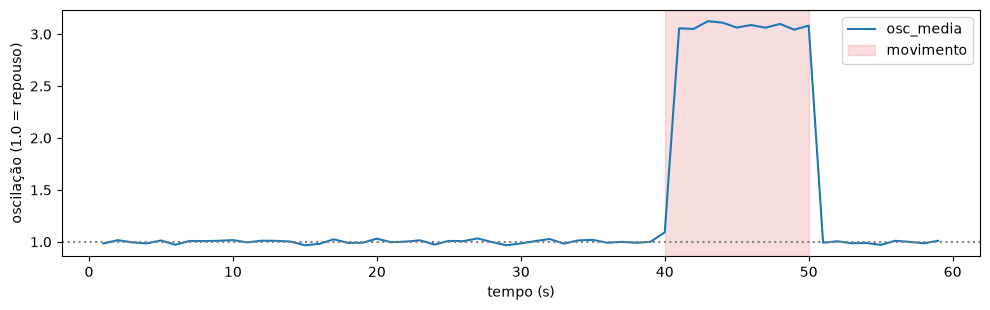

In [8]:
gen = sinal_sintetico()
ts, amp = [], []
for k in range(50 * 60):                      # 60 s a 50 pacotes/s
    t = k * 0.02
    pkt = parse_linha(gen.linha(t, movimento=(40 <= t < 50)))
    ts.append(pkt[0]); amp.append(pkt[1])
ts, amp = np.array(ts, float), np.stack(amp)

base, _ = calibrar(ts[ts < 30000], amp[ts < 30000])
tempos, matriz_features = features_sessao(base, ts, amp, passo=1000)
tab = pd.DataFrame(matriz_features, columns=nomes)
tab.insert(0, "t_s", tempos / 1000)
tab["situação"] = np.where((tab.t_s > 40) & (tab.t_s <= 50), "movimento", "repouso")
print(tab.groupby("situação")[nomes].mean().round(2))

plt.figure(figsize=(10, 3.2))
plt.plot(tab.t_s, tab.osc_media, label="osc_media")
plt.axvspan(40, 50, color="#d62728", alpha=0.15, label="movimento")
plt.axhline(1.0, color="gray", ls=":")
plt.xlabel("tempo (s)"); plt.ylabel("oscilação (1.0 = repouso)"); plt.legend(); plt.tight_layout(); plt.show()

## 4. Parte B: treino da árvore (`treinar_arvore.py`)

### 4.1 Estrutura das gravações
Cada gravação é um CSV gerado pelo script de captura. O **nome da pasta** é o rótulo, e a **data** vem do nome do arquivo:

```
dados/
  vazio/    csi_vazio_2026-10-17_16-33-53_8edca7e4.csv
  sentado/  csi_sentado_2026-10-16_15-04-10_5550a02f.csv
  andando/  csi_andando_2026-10-16_18-12-39_ead31c83.csv
```

Qualquer pasta que não seja `vazio` conta como pessoa. Das colunas do CSV, são usadas só o timestamp do ESP32, o tamanho do pacote e os 384 valores do CSI.

### 4.2 Leitura e filtragem das sessões
- `ler_csv` lê o arquivo em pedaços, mantém só as linhas com 384 bytes e converte cada par em amplitude. Guarda um cache (`.cache_csi`) para não reler arquivos grandes.
- `trecho_monotono` trata o caso de o ESP32 reiniciar no meio da gravação (o relógio volta a zero): fica o trecho mais longo.
- `descobrir_sessoes` monta a lista de sessões e marca as **descartadas**: taxa abaixo de 25 pacotes/s ou duração abaixo de 20 s. Com taxa baixa as janelas de 1 s não têm pacotes suficientes para medir oscilação.

In [9]:
def ler_csv(caminho, cache_dir):
    """Devolve (ts_ms, amp[n x 64]) de um CSV; usa cache .npz para nao reler arquivos grandes."""
    os.makedirs(cache_dir, exist_ok=True)
    chave = f"{os.path.basename(caminho)}_{os.path.getsize(caminho)}.npz"
    destino = os.path.join(cache_dir, chave)
    if os.path.exists(destino):
        d = np.load(destino)
        return d["ts"], d["amp"]
    cols = [4, 6] + list(range(7, 7 + tamanho))
    tipos = {c: np.float32 for c in cols}
    tipos[4] = np.float64
    ts, amp = [], []
    for ch in pd.read_csv(caminho, header=None, skiprows=1, usecols=cols, dtype=tipos,
                          chunksize=40000, on_bad_lines="skip", low_memory=False):
        ch = ch.dropna()
        ch = ch[ch.iloc[:, 1] == tamanho]
        if ch.empty:
            continue
        v = ch.iloc[:, 2:].to_numpy(np.float32)
        amp.append(np.hypot(v[:, 0::2], v[:, 1::2])[:, :n_sub])
        ts.append(ch.iloc[:, 0].to_numpy())
    if not ts:
        return np.array([]), np.zeros((0, n_sub), np.float32)
    ts, amp = np.concatenate(ts), np.concatenate(amp)
    np.savez(destino, ts=ts, amp=amp)
    return ts, amp


def trecho_monotono(ts, amp):
    """Se o ESP32 reiniciou no meio da gravacao (ts volta a zero), fica o trecho mais longo."""
    quebras = np.flatnonzero(np.diff(ts) < 0) + 1
    if len(quebras) == 0:
        return ts, amp
    lim = np.r_[0, quebras, len(ts)]
    i = int(np.argmax(np.diff(lim)))
    return ts[lim[i]:lim[i + 1]], amp[lim[i]:lim[i + 1]]


def descobrir_sessoes(pasta, cache_dir, min_pps, excluir):
    sessoes = []
    for arq in sorted(glob.glob(os.path.join(pasta, "*", "*.csv"))):
        nome = os.path.basename(arq)
        if any(e in nome for e in excluir):
            print(f"  (excluida por --excluir) {nome}")
            continue
        rotulo = os.path.basename(os.path.dirname(arq)).lower()
        m = re.search(r"(\d{4}-\d{2}-\d{2})", nome)
        dia = m.group(1) if m else "sem-data"
        ts, amp = ler_csv(arq, cache_dir)
        if len(ts) < 2:
            continue
        ts, amp = trecho_monotono(ts, amp)
        dur = (ts[-1] - ts[0]) / 1000.0
        pps = len(ts) / dur if dur > 0 else 0.0
        motivo = ""
        if pps < min_pps:
            motivo = f"taxa baixa ({pps:.1f} pacotes/s)"
        elif dur < 20:
            motivo = f"curta demais ({dur:.0f} s)"
        sessoes.append(dict(nome=nome.replace(".csv", ""), rotulo=rotulo, dia=dia, ts=ts, amp=amp,
                            pps=pps, dur=dur, motivo=motivo))
    return sessoes

### 4.3 Montagem do dataset: normalização por dia
O sinal de WiFi **muda de um dia para o outro** mesmo sem ninguém no quarto. Por isso, para cada dia:

1. escolhe-se a gravação de **vazio mais longa** do dia como repouso;
2. calibra-se com os primeiros 60 s dela (mesma calibração da demonstração);
3. todas as sessões desse dia são medidas em unidades desse repouso.

Detalhes: as janelas da própria calibração não entram no treino, os 5 s iniciais e finais das sessões com pessoa são cortados (entrada e saída do quarto viram rótulo errado) e dias **sem vazio utilizável** ficam de fora, porque sem o repouso do dia não dá para normalizar.

In [10]:
def montar_dataset(sessoes, calib_s, corte):
    linhas, avisos = [], []
    for dia in sorted({s["dia"] for s in sessoes}):
        do_dia = [s for s in sessoes if s["dia"] == dia and not s["motivo"]]
        vazios = [s for s in do_dia if s["rotulo"] == "vazio"]
        if not vazios:
            if do_dia:
                avisos.append(f"{dia}: sem gravacao de vazio utilizavel -> {len(do_dia)} sessao(oes) ficaram de fora "
                              f"(sem repouso do dia nao da para normalizar)")
            continue
        ref = max(vazios, key=lambda s: s["dur"])
        m = ref["ts"] < ref["ts"][0] + calib_s * 1000
        base, _ = calibrar(ref["ts"][m], ref["amp"][m])
        if base is None:
            avisos.append(f"{dia}: calibracao falhou em {ref['nome']}")
            continue
        for s in do_dia:
            t, matriz_features = features_sessao(base, s["ts"], s["amp"], passo=1000)
            if len(t) == 0:
                continue
            keep = np.ones(len(t), bool)
            if s is ref:
                keep &= t >= (calib_s + 1) * 1000          # nao reaproveita a janela de calibracao
            if s["rotulo"] != "vazio" and s["dur"] > 10 * corte:
                keep &= (t >= corte * 1000) & (t <= (s["dur"] - corte) * 1000)
            for ti, fi in zip(t[keep], matriz_features[keep]):
                linhas.append(dict(sessao=s["nome"][:40], rotulo=s["rotulo"], dia=dia,
                                   bloco=int(ti // 120000), y=int(s["rotulo"] != "vazio"),
                                   **dict(zip(nomes, fi))))
    return pd.DataFrame(linhas), avisos

### 4.4 Árvore e validação
A árvore é rasa (profundidade 3) e exige no mínimo 50 janelas por folha, o que evita decorar. `class_weight="balanced"` compensa o desequilíbrio entre as classes.

A validação é feita de três jeitos, do menos para o mais exigente:

- **A) Dentro do dia:** blocos de 2 min separados entre treino e teste.
- **B) Entre dias:** treina num dia e testa em outro, cada dia com o seu repouso.
- **C) Sessão inteira de fora:** treina com todas as outras sessões e testa na que ficou de fora. Quando a sessão de fora é de **vazio**, o resultado é um **controle negativo**: um vazio gravado em outro momento tem que continuar sendo vazio.

Cada resultado aparece **por janela** e **com memória** (alerta se pelo menos 2 das últimas 5 janelas acusam movimento, a mesma ideia da demonstração).

In [11]:
def nova_arvore(args):
    return DecisionTreeClassifier(max_depth=args.profundidade, min_samples_leaf=args.folha,
                                  class_weight="balanced", random_state=0)


def com_memoria(pred):
    """Mesma ideia da demo: alerta se >= 2 das ultimas 5 janelas (1 s) acusam movimento."""
    f = np.asarray(pred, int)
    return np.array([f[max(0, i - 4):i + 1].sum() >= 2 for i in range(len(f))])


def taxa(pred, y_real):
    return float(np.mean(pred)) if len(pred) else float("nan")


def avaliar(dataset, args):
    atributos = nomes

    print("\n" + "=" * 72)
    print("A) DENTRO DO DIA (blocos de 2 min separados entre treino e teste)")
    print("=" * 72)
    for dia, dataset_dia in dataset.groupby("dia"):
        if dataset_dia.y.nunique() < 2:
            continue
        if (dataset_dia.y == 1).sum() < 100 or (dataset_dia.y == 0).sum() < 100:
            print(f"  {dia}: poucas janelas ({int((dataset_dia.y == 1).sum())} de pessoa, "
                  f"{int((dataset_dia.y == 0).sum())} de vazio) -> teste por blocos nao e confiavel, ignorado")
            continue
        g = dataset_dia.sessao + "_" + dataset_dia.bloco.astype(str)
        pred = np.zeros(len(dataset_dia), int)
        for tr, te in GroupKFold(5).split(dataset_dia, dataset_dia.y, g):
            m = nova_arvore(args).fit(dataset_dia.iloc[tr][atributos], dataset_dia.y.iloc[tr])
            pred[te] = m.predict(dataset_dia.iloc[te][atributos])
        dataset_dia = dataset_dia.assign(p=pred)
        for s, dataset_sessao in dataset_dia.groupby("sessao"):
            nome = "falso alarme" if dataset_sessao.y.iloc[0] == 0 else "deteccao   "
            print(f"  {dia} {dataset_sessao.rotulo.iloc[0]:8s} {nome}: {taxa(dataset_sessao.p, None):6.1%}   ({s[:28]})")

    print("\n" + "=" * 72)
    print("B) ENTRE DIAS (treina num dia, testa em outro, cada dia com o seu repouso)")
    print("=" * 72)
    dias = [d for d, dataset_dia in dataset.groupby("dia") if dataset_dia.y.nunique() == 2 and (dataset_dia.y == 1).sum() >= 20]
    feito = False
    for d_tr in dias:
        for d_te in dataset.dia.unique():
            dataset_teste = dataset[dataset.dia == d_te]
            if d_te == d_tr or dataset_teste.y.nunique() < 2:
                continue
            m = nova_arvore(args).fit(dataset[dataset.dia == d_tr][atributos], dataset[dataset.dia == d_tr].y)
            dataset_teste = dataset_teste.assign(p=m.predict(dataset_teste[atributos]))
            n_pos = int((dataset[dataset.dia == d_tr].y == 1).sum())
            aviso = "   <- POUCOS dados de pessoa no treino, nao confie" if n_pos < 100 else ""
            print(f"  treino {d_tr} ({n_pos} janelas de pessoa) -> teste {d_te}{aviso}")
            for s, dataset_sessao in dataset_teste.groupby("sessao"):
                nome = "falso alarme" if dataset_sessao.y.iloc[0] == 0 else "deteccao   "
                print(f"      {dataset_sessao.rotulo.iloc[0]:8s} {nome}: {taxa(dataset_sessao.p, None):6.1%}   ({s[:28]})")
            feito = True
    if not feito:
        print("  (precisa de pelo menos 2 dias, cada um com vazio e pessoa)")

    print("\n" + "=" * 72)
    print("C) DEIXANDO UMA SESSAO INTEIRA DE FORA  (o teste mais honesto)")
    print("   Em 'vazio', o resultado e o CONTROLE NEGATIVO: vazio gravado em outro momento.")
    print("=" * 72)
    print(f"  {'sessao':42s} {'por janela':>11s} {'com memoria':>12s}")
    resultados = []
    for s in dataset.sessao.unique():
        tr, te = dataset[dataset.sessao != s], dataset[dataset.sessao == s]
        if tr.y.nunique() < 2:
            continue
        m = nova_arvore(args).fit(tr[atributos], tr.y)
        p = m.predict(te[atributos])
        rot = "FALSO ALARME" if te.y.iloc[0] == 0 else "deteccao"
        print(f"  {te.rotulo.iloc[0]:8s} {s[7:30]:22s} {rot:13s}{np.mean(p):6.1%}  {np.mean(com_memoria(p)):9.1%}")
        resultados.append(pd.DataFrame({"sessao": te.sessao.values, "rotulo": te.rotulo.values,
                                        "y": te.y.values, "pred": p,
                                        "pred_mem": com_memoria(p).astype(int)}))
    return pd.concat(resultados, ignore_index=True) if resultados else pd.DataFrame()

### 4.5 Comando de treino
O comando faz tudo de uma vez: lê as sessões, monta o dataset, valida, treina a árvore final, imprime as regras e salva `modelo_arvore.joblib` e o desenho `modelo_arvore.png`.

| Argumento | Padrão | Para que serve |
|---|---|---|
| `--dados` | `dados` | pasta com as subpastas por classe |
| `--saida` | `modelo_arvore.joblib` | arquivo do modelo |
| `--calib-s` | `60` | segundos de repouso usados como base do dia |
| `--min-pps` | `25` | descarta sessões com menos pacotes por segundo |
| `--profundidade` | `3` | profundidade máxima da árvore |
| `--folha` | `50` | mínimo de janelas por folha |
| `--corte` | `5` | segundos cortados do início e do fim das sessões com pessoa |
| `--excluir` | nenhum | trechos de nome de arquivo para deixar de fora (teste com sessão nunca vista) |
| `--sem-avaliacao` | desligado | pula a validação (só treina e salva) |
| `--cache` | `.cache_csi` | pasta do cache |

> Ajuste `--dados` para a pasta onde estão as gravações (por exemplo `../dados`). Na primeira execução a leitura dos CSVs demora; as próximas usam o cache.

In [12]:
def parser_treino():
    p = parser_notebook(prog="%treinar_arvore", description="Treina a árvore de decisão do radar CSI.")
    p.add_argument("--dados", default="dados", help="Pasta com subpastas por classe (vazio, sentado, ...).")
    p.add_argument("--saida", default="modelo_arvore.joblib")
    p.add_argument("--calib-s", type=float, default=60.0, help="Segundos de repouso usados como base do dia.")
    p.add_argument("--min-pps", type=float, default=25.0, help="Descarta sessões com menos pacotes/s.")
    p.add_argument("--profundidade", type=int, default=3)
    p.add_argument("--folha", type=int, default=50, help="Mínimo de janelas por folha da árvore.")
    p.add_argument("--corte", type=float, default=5.0, help="Segundos cortados do início/fim de sessões com pessoa.")
    p.add_argument("--excluir", nargs="*", default=[], help="Trechos de nome de arquivo para deixar de fora.")
    p.add_argument("--sem-avaliacao", action="store_true", help="Pula a validação.")
    p.add_argument("--cache", default=".cache_csi")
    return p


def treinar(args):
    print("Lendo sessoes...")
    sessoes = descobrir_sessoes(args.dados, args.cache, args.min_pps, args.excluir)
    print(f"\n{'classe':9s} {'dia':11s} {'min':>6s} {'pkt/s':>6s}  sessao")
    for s in sessoes:
        marca = "  <- DESCARTADA: " + s["motivo"] if s["motivo"] else ""
        print(f"{s['rotulo']:9s} {s['dia']:11s} {s['dur'] / 60:6.1f} {s['pps']:6.1f}  {s['nome'][-24:]}{marca}")

    dataset, avisos = montar_dataset(sessoes, args.calib_s, args.corte)
    for a in avisos:
        print("AVISO:", a)
    if dataset.empty or dataset.y.nunique() < 2:
        print("Dados insuficientes: preciso de vazio E pessoa, no mesmo dia, com taxa boa.")
        return
    print(f"\nJanelas de 1 s: {len(dataset)} | vazio={int((dataset.y == 0).sum())} | pessoa={int((dataset.y == 1).sum())} "
          f"| sessoes={dataset.sessao.nunique()} | dias={dataset.dia.nunique()}")

    loso = pd.DataFrame() if args.sem_avaliacao else avaliar(dataset, args)

    modelo = nova_arvore(args).fit(dataset[nomes], dataset.y)
    print("\n" + "=" * 72)
    print("ARVORE FINAL (treinada com todas as sessoes)")
    print("=" * 72)
    print(export_text(modelo, feature_names=nomes))
    imp = sorted(zip(nomes, modelo.feature_importances_), key=lambda x: -x[1])
    print("Importancia das medidas:", ", ".join(f"{n}={v:.2f}" for n, v in imp if v > 0))
    print("(valores das medidas: 1.0 = repouso do dia; quanto maior, mais o sinal balanca)")

    os.makedirs("modelos", exist_ok=True)
    caminho_modelo = os.path.join("modelos", os.path.basename(args.saida))
    joblib.dump({"modelo": modelo, "features": nomes, "versao": 1}, caminho_modelo)
    print(f"\nModelo salvo em {caminho_modelo}")

    os.makedirs("foto_arvores_decisao", exist_ok=True)
    png = os.path.join("foto_arvores_decisao", os.path.splitext(os.path.basename(args.saida))[0] + ".png")

    fig = plt.figure(figsize=(20, 8))
    plot_tree(modelo, feature_names=nomes, class_names=["vazio", "movimento"],
              filled=True, rounded=True, fontsize=8, precision=2)
    fig.savefig(png, dpi=110, bbox_inches="tight")
    plt.close(fig)
    print(f"Desenho da arvore salvo em {png}")

    treino[args.saida] = dict(sessoes=sessoes, dataset=dataset, modelo=modelo, loso=loso, args=args)


registrar_comando("treinar_arvore", parser_treino, treinar)

In [13]:
%treinar_arvore --dados dados

Lendo sessoes...

classe    dia            min  pkt/s  sessao
andando   2026-10-15    16.8    1.1  -10-15_18-46-10_a8d0e595  <- DESCARTADA: taxa baixa (1.1 pacotes/s)
andando   2026-10-16     6.0   49.8  -10-16_18-12-39_ead31c83
dormindo  2026-10-15     1.6    1.1  -10-15_23-43-03_2dd06e8c  <- DESCARTADA: taxa baixa (1.1 pacotes/s)
dormindo  2026-10-15     0.4   50.0  -10-15_23-45-09_af1239c2
sentado   2026-10-15    18.4    1.2  -10-15_19-52-56_7559963a  <- DESCARTADA: taxa baixa (1.2 pacotes/s)
sentado   2026-10-15    20.7    1.1  -10-15_21-48-51_7d8db410  <- DESCARTADA: taxa baixa (1.1 pacotes/s)
sentado   2026-10-15    16.9    1.0  -10-15_22-47-43_3220801e  <- DESCARTADA: taxa baixa (1.0 pacotes/s)
sentado   2026-10-15     0.4   50.2  -10-15_23-29-04_775cb428
sentado   2026-10-16     1.3   15.1  -10-16_10-08-46_1231fca5  <- DESCARTADA: taxa baixa (15.1 pacotes/s)
sentado   2026-10-16    10.8    7.6  -10-16_10-15-51_98eadacb  <- DESCARTADA: taxa baixa (7.6 pacotes/s)
sentado   2026-1

### 4.6 Resultados do treino
As células seguintes usam o que o comando acima deixou na memória (`treino`).

#### Sessões e classes

In [14]:
resultado_treino = treino["modelo_arvore.joblib"]
tabela = pd.DataFrame([{
    "classe": s["rotulo"], "dia": s["dia"], "duração (min)": round(s["dur"] / 60, 1),
    "pacotes/s": round(s["pps"], 1),
    "situação": ("descartada: " + s["motivo"]) if s["motivo"] else "usada",
    "sessão": s["nome"][-24:]} for s in resultado_treino["sessoes"]])
tabela

,classe,dia,duração (min),pacotes/s,situação,sessão
0,andando,2026-10-15,16.8,1.1,descartada: taxa baixa (1.1 pacotes/s),-10-15_18-46-10_a8d0e595
1,andando,2026-10-16,6.0,49.8,usada,-10-16_18-12-39_ead31c83
2,dormindo,2026-10-15,1.6,1.1,descartada: taxa baixa (1.1 pacotes/s),-10-15_23-43-03_2dd06e8c
3,dormindo,2026-10-15,0.4,50.0,usada,-10-15_23-45-09_af1239c2
4,sentado,2026-10-15,18.4,1.2,descartada: taxa baixa (1.2 pacotes/s),-10-15_19-52-56_7559963a
5,sentado,2026-10-15,20.7,1.1,descartada: taxa baixa (1.1 pacotes/s),-10-15_21-48-51_7d8db410
6,sentado,2026-10-15,16.9,1.0,descartada: taxa baixa (1.0 pacotes/s),-10-15_22-47-43_3220801e
7,sentado,2026-10-15,0.4,50.2,usada,-10-15_23-29-04_775cb428
8,sentado,2026-10-16,1.3,15.1,descartada: taxa baixa (15.1 pacotes/s),-10-16_10-08-46_1231fca5
9,sentado,2026-10-16,10.8,7.6,descartada: taxa baixa (7.6 pacotes/s),-10-16_10-15-51_98eadacb


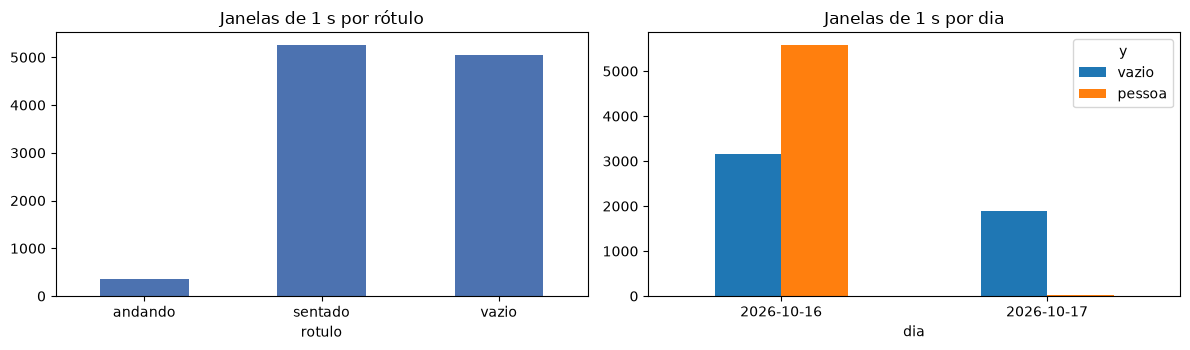

Baseline (sempre prever a classe majoritária): 0.527


In [15]:
dataset_treino = resultado_treino["dataset"]
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.6))
dataset_treino.groupby("rotulo").size().plot.bar(ax=eixos[0], color="#4c72b0", rot=0, title="Janelas de 1 s por rótulo")
(dataset_treino.groupby(["dia", "y"]).size().unstack(fill_value=0).rename(columns={0: "vazio", 1: "pessoa"})
    .plot.bar(ax=eixos[1], rot=0, title="Janelas de 1 s por dia"))
plt.tight_layout(); plt.show()
print(f"Baseline (sempre prever a classe majoritária): {max((dataset_treino.y == 0).mean(), (dataset_treino.y == 1).mean()):.3f}")

> **Observação:** poucas sessões sobraram depois do filtro de taxa (as gravações mais antigas foram feitas a ~1 pacote/s) e há só **2 dias** utilizáveis. Os resultados abaixo têm que ser lidos com isso em mente.

#### As medidas separam vazio de pessoa?
Distribuição de cada medida (valores relativos ao repouso do dia; 1,0 = parado). Os valores acima do percentil 99 foram cortados só para facilitar a leitura do gráfico.

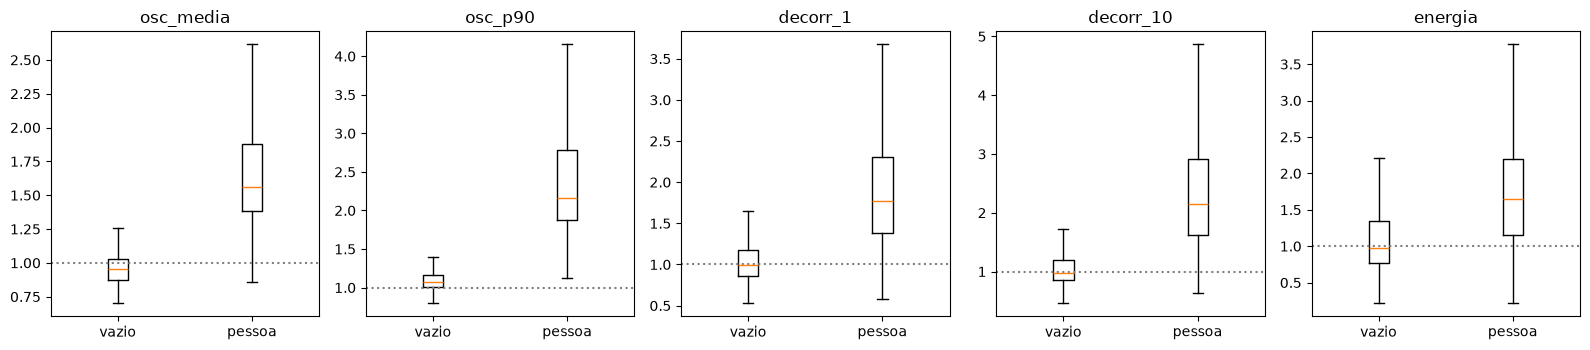

In [16]:
fig, eixos = plt.subplots(1, len(nomes), figsize=(16, 3.6))
for ax, nome in zip(eixos, nomes):
    teto = dataset_treino[nome].quantile(0.99)
    ax.boxplot([dataset_treino.loc[dataset_treino.y == 0, nome].clip(upper=teto), dataset_treino.loc[dataset_treino.y == 1, nome].clip(upper=teto)],
               showfliers=False)
    ax.set_xticklabels(["vazio", "pessoa"]); ax.set_title(nome); ax.axhline(1.0, color="gray", ls=":")
plt.tight_layout(); plt.show()

#### Avaliação com uma sessão inteira de fora (a mais exigente)
Os números vêm do teste **C** do comando: cada sessão foi testada por um modelo que nunca a viu. A acurácia geral é puxada pela sessão de 94 min, então vale olhar também a acurácia balanceada e a tabela por sessão.

Acurácia:             0.9250   (baseline: 0.5268)
Acurácia balanceada:  0.9237

              precision    recall  f1-score   support

       vazio      0.939     0.900     0.919      5041
   movimento      0.913     0.947     0.930      5611

    accuracy                          0.925     10652
   macro avg      0.926     0.924     0.925     10652
weighted avg      0.925     0.925     0.925     10652



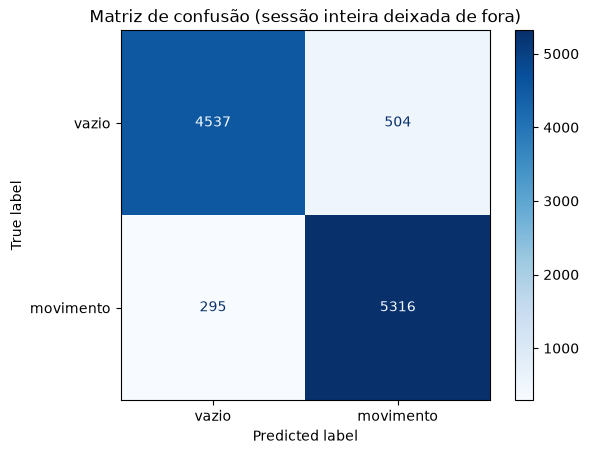

In [17]:
loso = resultado_treino["loso"]
base_maj = max((loso.y == 0).mean(), (loso.y == 1).mean())
print(f"Acurácia:             {accuracy_score(loso.y, loso.pred):.4f}   (baseline: {base_maj:.4f})")
print(f"Acurácia balanceada:  {balanced_accuracy_score(loso.y, loso.pred):.4f}\n")
print(classification_report(loso.y, loso.pred, target_names=["vazio", "movimento"], digits=3))
ConfusionMatrixDisplay.from_predictions(loso.y, loso.pred, display_labels=["vazio", "movimento"], cmap="Blues")
plt.title("Matriz de confusão (sessão inteira deixada de fora)"); plt.show()

In [18]:
(loso.groupby(["rotulo", "sessao"])
     .agg(janelas=("y", "size"), por_janela=("pred", "mean"), com_memoria=("pred_mem", "mean"))
     .rename(columns={"por_janela": "% em alerta (por janela)", "com_memoria": "% em alerta (com memória)"})
     .round(3))

janelas  \
rotulo  sessao                                              
andando csi_andando_2026-10-16_18-12-39_ead31c83      351   
sentado csi_sentado_2026-10-16_15-04-10_5550a02f     5232   
        csi_sentado_2026-10-17_23-34-47_a98e5769       28   
vazio   csi_vazio_2026-10-16_18-24-53_51bde2bf       3158   
        csi_vazio_2026-10-17_16-33-53_8edca7e4       1883   

                                                  % em alerta (por janela)  \
rotulo  sessao                                                               
andando csi_andando_2026-10-16_18-12-39_ead31c83                     1.000   
sentado csi_sentado_2026-10-16_15-04-10_5550a02f                     0.945   
        csi_sentado_2026-10-17_23-34-47_a98e5769                     0.821   
vazio   csi_vazio_2026-10-16_18-24-53_51bde2bf                       0.147   
        csi_vazio_2026-10-17_16-33-53_8edca7e4                       0.021   

                                                  % em alerta (com memória)  
rotulo  sessao                                                               
andando csi_andando_2026-10-16_18-12-39_ead31c83                      0.997  
sentado csi_sentado_2026-10-16_15-04-10_5550a02f                      0.984  
        csi_sentado_2026-10-17_23-34-47_a98e5769                      0.964  
vazio   csi_vazio_2026-10-16_18-24-53_51bde2bf                        0.168  
        csi_vazio_2026-10-17_16-33-53_8edca7e4                        0.033

> **Como ler a tabela:** nas linhas de `vazio`, "% em alerta" é o **falso alarme** (quanto menor, melhor); nas demais, é a **detecção** (quanto maior, melhor).

### 4.7 Atenção: por que o formato médio do espectro ficou de fora (vazamento de sessão)
Uma medida que parecia ótima era a **distância entre o formato médio do espectro da janela e o do repouso**. Em validações comuns ela dava **AUC 1,000**, e isso é um sinal de alerta: ela pode estar medindo *"esta gravação é diferente da gravação de calibração"* em vez de *"há alguém aqui"*.

O controle abaixo mede essa distância usando como repouso cada gravação de vazio. Se a medida detectasse presença, os **vazios de outros dias** ficariam perto de 1 (como o próprio repouso). Se identificasse a sessão, ficariam tão longe quanto as sessões com pessoa.

In [19]:
def distancia_ao_repouso(ref, alvo):
    """Mediana da distância entre o formato médio do espectro de `alvo` e o do repouso de `ref`
    (relativa à variação normal dentro do próprio repouso)."""
    m = ref["ts"] < ref["ts"][0] + 60000
    base, _ = calibrar(ref["ts"][m], ref["amp"][m])
    x_ref, _ = normalizar(ref["amp"][m], base.mask)
    mu = x_ref.mean(axis=0)

    def dists(ts, amp):
        x, _ = normalizar(amp, base.mask)
        return np.array([np.linalg.norm(x[i0:i1].mean(axis=0) - mu) for i0, i1, _ in janelas(ts, 1000)])

    d_ref = np.median(dists(ref["ts"][m], ref["amp"][m]))
    d = dists(alvo["ts"], alvo["amp"])
    if alvo is ref:
        d = d[60:]                       # ignora a parte usada na calibração
    return float(np.median(d) / d_ref)


usaveis = [s for s in resultado_treino["sessoes"] if not s["motivo"]]
vazios = sorted([s for s in usaveis if s["rotulo"] == "vazio"], key=lambda s: -s["dur"])
linhas = []
for s in usaveis:
    linha = {"classe": s["rotulo"], "dia": s["dia"], "sessão": s["nome"][-8:]}
    for ref in vazios:
        linha[f"distância ao repouso de {ref['dia']}"] = round(distancia_ao_repouso(ref, s), 1)
    linhas.append(linha)
pd.DataFrame(linhas)

,classe,dia,sessão,distância ao repouso de 2026-10-16,distância ao repouso de 2026-10-17
0,andando,2026-10-16,ead31c83,24.3,12.7
1,dormindo,2026-10-15,af1239c2,45.8,12.3
2,sentado,2026-10-15,775cb428,45.0,10.8
3,sentado,2026-10-16,5550a02f,32.1,10.0
4,sentado,2026-10-17,a98e5769,58.3,13.1
5,sentado,2026-10-18,590f2e7d,60.5,13.3
6,vazio,2026-10-16,51bde2bf,1.3,12.5
7,vazio,2026-10-17,8edca7e4,50.8,1.4


> **Leitura:** em cada coluna, o vazio que serviu de repouso fica perto de 1, mas o **vazio de outro dia** fica tão longe quanto as sessões com pessoa. A medida identifica a sessão, não a presença, e por isso **não foi usada**. Um modelo treinado com ela teria acurácia altíssima na validação e falharia na demonstração.
>
> As cinco medidas da Parte A são todas relativas à *variação* do sinal, que é bem menos sensível a essa diferença entre dias (mas não imune, como mostram o controle negativo da seção 4.6 e a seção 6).

### 4.8 Interpretação do modelo
#### Importância das medidas

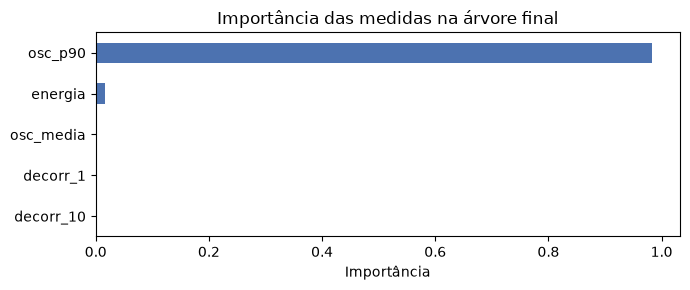

In [20]:
imp = pd.Series(resultado_treino["modelo"].feature_importances_, nomes).sort_values(ascending=False)
imp[::-1].plot.barh(figsize=(7, 3), color="#4c72b0")
plt.title("Importância das medidas na árvore final"); plt.xlabel("Importância"); plt.tight_layout(); plt.show()

#### Visualização da árvore
Cada nó mostra a pergunta (por exemplo, `osc_p90 <= 1.41`: "o sinal oscila mais de 1,41 vez o normal?"). Os nós laranja concentram janelas de *vazio* e os azuis, de *movimento*. Como `class_weight="balanced"`, os valores de `value` são pesos, não contagens.

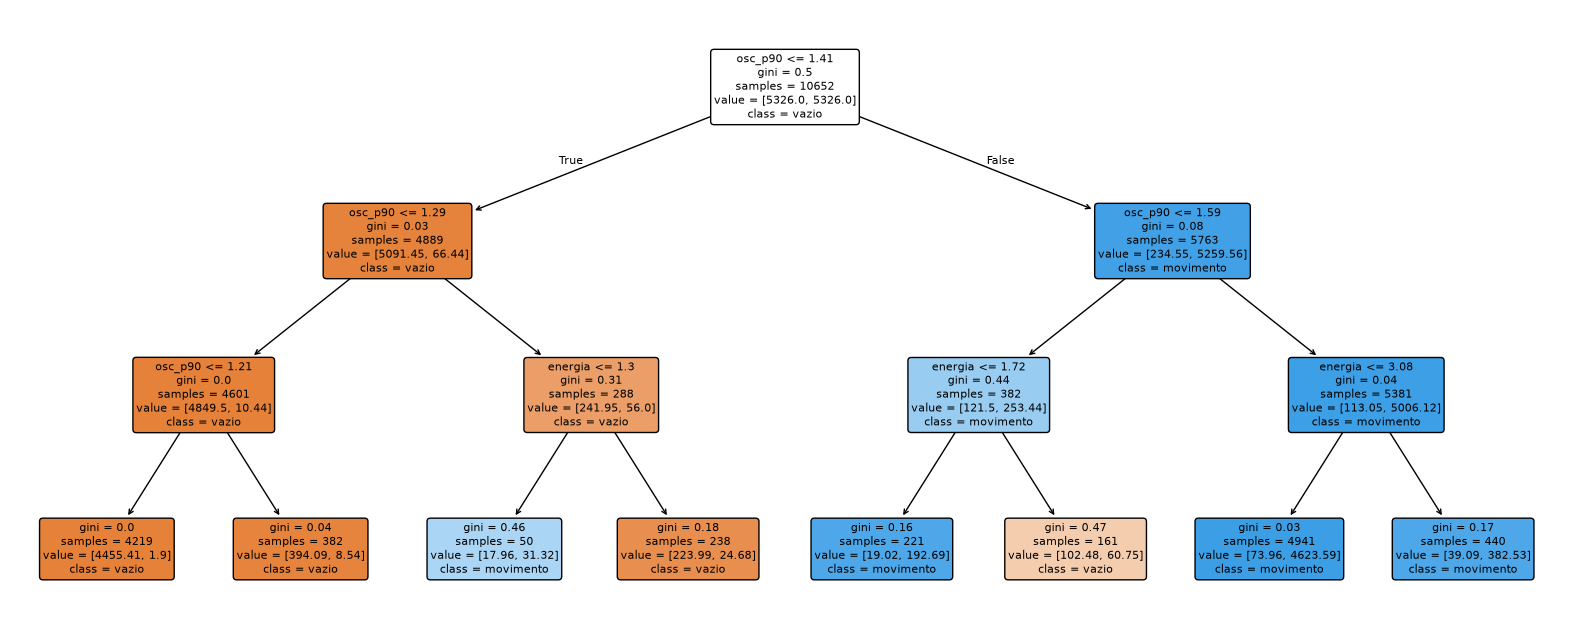

|--- osc_p90 <= 1.41
|   |--- osc_p90 <= 1.29
|   |   |--- osc_p90 <= 1.21
|   |   |   |--- class: 0
|   |   |--- osc_p90 >  1.21
|   |   |   |--- class: 0
|   |--- osc_p90 >  1.29
|   |   |--- energia <= 1.30
|   |   |   |--- class: 1
|   |   |--- energia >  1.30
|   |   |   |--- class: 0
|--- osc_p90 >  1.41
|   |--- osc_p90 <= 1.59
|   |   |--- energia <= 1.72
|   |   |   |--- class: 1
|   |   |--- energia >  1.72
|   |   |   |--- class: 0
|   |--- osc_p90 >  1.59
|   |   |--- energia <= 3.08
|   |   |   |--- class: 1
|   |   |--- energia >  3.08
|   |   |   |--- class: 1



In [21]:
plt.figure(figsize=(20, 8))
plot_tree(resultado_treino["modelo"], feature_names=nomes, class_names=["vazio", "movimento"],
          filled=True, rounded=True, fontsize=8, precision=2)
plt.show()
print(export_text(resultado_treino["modelo"], feature_names=nomes))

> **Observação:** a árvore é, na prática, **um corte em `osc_p90`** (em torno de 1,3 a 1,4 vez o normal). Os níveis de baixo mexem em poucas janelas. Com os dados atuais o sinal tem basicamente uma dimensão útil; mais gravações podem justificar uma árvore mais rica. Use `--profundidade 2` para uma versão mais simples.

## 5. Parte C: demonstração ao vivo (`demo_ao_vivo.py`)
A demonstração faz três coisas ao mesmo tempo:

1. **Captura:** uma thread manda pacotes UDP ao ESP32 e outra lê a serial.
2. **Detecção:** o `detector` calibra no local e, a cada 0,5 s, calcula as 5 medidas do último 1 s.
3. **Painel:** desenha o gráfico dentro da célula, 2 vezes por segundo.

### 5.1 O detector
Duas fases:

- **Calibrando:** junta pacotes por `--calibracao` segundos (a área do link deve ficar **parada**) e chama `calibrar`.
- **Ao vivo:** a cada 0,5 s decide de um de dois jeitos. **Sem `--modelo`**, compara a `osc_media` com um limiar (`normal + k × ruído`). **Com `--modelo`**, a árvore devolve a probabilidade de movimento e o limiar é 0,5.

Nos dois casos há **memória**: o alerta só dispara se 4 das últimas 10 leituras (cerca de 2 s) passarem do limiar, o que evita alarme por um pico isolado.

In [22]:
class detector:
    def __init__(self, calib_s=60.0, sensib=1.0, k=3.0, n=10, m=4, modelo=None):
        self.calib_s, self.sensib, self.k, self.n, self.m = calib_s, sensib, k, n, m
        self.modelo = modelo
        self.lock = threading.Lock()
        self.reset()

    def reset(self):
        self.fase = "calibrando"
        self.calib = []
        self.base = None
        self.med = self.sigma = None
        self.janela = deque()
        self.ultimo_calc = None
        self.ultimo_ts = None
        self.flags = deque(maxlen=self.n)
        self.historico = deque(maxlen=240)
        self.valor = None
        self.alerta = False
        self.pps = 0
        self.prog = 0.0
        self.msg = ""
        self.total = 0

    @property
    def limiar(self):
        if self.modelo is not None:                       # arvore: limiar de probabilidade
            return float(np.clip(0.5 / self.sensib, 0.05, 0.95))
        return self.med + (self.k / self.sensib) * self.sigma

    def _finalizar_calibracao(self):
        ts = np.array([t for t, _ in self.calib], dtype=np.float64)
        arr = np.stack([a for _, a in self.calib])
        pps = len(ts) / max((ts[-1] - ts[0]) / 1000.0, 1e-9)
        base, matriz_features = calibrar(ts, arr)
        if base is None:
            self.msg = f"Calibracao falhou: so {pps:.0f} pacotes/s. Tentando de novo..."
            self.calib = []
            return
        self.base = base
        z = matriz_features[:, 0]
        self.med = float(np.median(z))
        self.sigma = max(1.4826 * float(np.median(np.abs(z - self.med))), 0.05 * self.med)
        self.fase = "ao_vivo"
        aviso = "  [AVISO: taxa baixa, o ideal e ~50/s]" if pps < 35 else ""
        modo = "ARVORE" if self.modelo is not None else f"limiar={self.med + self.k * self.sigma:.3f}"
        self.msg = f"Calibrado: {pps:.0f} pacotes/s | modo {modo}{aviso}"

    def add(self, ts, amp):
        """Processa um pacote. Devolve True quando calculou um valor novo."""
        with self.lock:
            self.total += 1
            if self.ultimo_ts is not None and ts < self.ultimo_ts:   # ESP32 reiniciou
                self.janela.clear()
                self.ultimo_calc = None
                self.calib = []
            self.ultimo_ts = ts

            if self.fase == "calibrando":
                self.calib.append((ts, amp))
                dec = (ts - self.calib[0][0]) / 1000.0
                self.prog = min(dec / self.calib_s, 1.0)
                if dec >= self.calib_s:
                    self._finalizar_calibracao()
                return False

            self.janela.append((ts, amp[self.base.mask]))
            while self.janela and self.janela[0][0] <= ts - janela_ms:
                self.janela.popleft()
            self.pps = len(self.janela)

            if self.ultimo_calc is None or ts - self.ultimo_calc >= passo_ms:
                self.ultimo_calc = ts
                if len(self.janela) >= min_pkts:
                    raw = np.stack([r for _, r in self.janela])
                    x = raw / np.clip(raw.mean(axis=1, keepdims=True), 1e-9, None)
                    f = features_janela(self.base, x, raw)
                    if self.modelo is not None:
                        self.valor = float(self.modelo.predict_proba(f[None, :])[0, 1])
                    else:
                        self.valor = float(f[0])
                    self.flags.append(self.valor > self.limiar)
                    self.alerta = sum(self.flags) >= self.m
                    self.historico.append(self.valor)
                    return True
                self.valor = None
            return False

    def snapshot(self):
        with self.lock:
            return dict(fase=self.fase, prog=self.prog, valor=self.valor, alerta=self.alerta,
                        pps=self.pps, msg=self.msg, sensib=self.sensib, total=self.total,
                        arvore=self.modelo is not None,
                        limiar=(self.limiar if self.fase == "ao_vivo" else None),
                        hist=list(self.historico))

### 5.2 Fontes de pacotes
Cada fonte roda numa thread e entrega os pacotes ao detector:

- `fonte_serial`: lê a porta serial em blocos, com buffer grande (ler linha a linha era lento demais e perdia pacotes).
- `disparar_udp`: manda um pacote ao ESP32 a cada 20 ms; é isso que faz o roteador gerar tráfego e o ESP32 medir o sinal.
- `fonte_simulador`: sinal sintético com dois períodos de movimento (ensaio sem hardware).
- `fonte_replay`: reexibe gravações reais do CSV, calibrando com uma e analisando outra.

In [23]:
def achar_porta():
    portas = list(serial.tools.list_ports.comports())
    chaves = ("CP210", "CH340", "USB-SERIAL", "USB SERIAL", "UART")
    cand = [p for p in portas if any(c in (p.description or "").upper() for c in chaves)]

    if not portas:
        print("Nenhuma porta serial encontrada. Confira o cabo USB (precisa ser de dados) e o driver CP210x/CH340.")
    else:
        print("Nao consegui escolher a porta sozinho. Portas encontradas:")
        for p in portas:
            print(f"  {p.device}  ({p.description})")
        print("Rode de novo com --serial <porta>.")
    return None

    print("Nao consegui escolher a porta sozinho. Portas encontradas:")
    for p in portas:
        print(f"  {p.device}  ({p.description})")
    raise SystemExit("Rode de novo com --serial <porta>.")


def fonte_serial(porta, baud, processar, parar, erros, contagem):
    try:
        ser = serial.Serial(porta, baud, timeout=0.1)
        try:
            ser.set_buffer_size(rx_size=1 << 20, tx_size=1 << 14)   # so existe no Windows
        except Exception:
            pass
        
        ser.reset_input_buffer()
        buf = bytearray()
        while not parar.is_set():
            dados = ser.read(max(ser.in_waiting, 1))
            if not dados:
                continue
            buf += dados
            while True:
                i = buf.find(b"\n")
                if i < 0:
                    break
                linha = bytes(buf[:i]).decode("utf-8", errors="replace").strip()
                del buf[:i + 1]
                pkt = parse_linha(linha)
                if pkt:
                    processar(*pkt)
                else:
                    contagem["invalidas"] += 1
            if len(buf) > 50000:      # lixo sem quebra de linha
                buf.clear()
        ser.close()
    except Exception as e:
        erros.append(f"Erro na serial: {e}")
        parar.set()


def disparar_udp(ip, porta, intervalo_s, parar):
    """Manda pacotes ao ESP32 em ritmo fixo (e o que gera o CSI)."""
    sock = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
    prox = time.perf_counter()
    while not parar.is_set():
        try:
            sock.sendto(b"radar", (ip, porta))
        except OSError:
            pass
        prox += intervalo_s
        atraso = prox - time.perf_counter()
        if atraso > 0:
            time.sleep(atraso)
        else:
            prox = time.perf_counter()
    sock.close()


def fonte_simulador(processar, parar, calib_s):
    """Sinal sintético a 50 pacotes/s: parado, com dois períodos de 'movimento' depois da calibração."""
    gen = sinal_sintetico()
    t0 = time.monotonic()
    prox = t0
    while not parar.is_set():
        t = time.monotonic() - t0
        mov = (calib_s + 8 <= t < calib_s + 14) or (calib_s + 22 <= t < calib_s + 28)
        pkt = parse_linha(gen.linha(t, mov))
        if pkt:
            processar(*pkt)
        prox += 0.02
        atraso = prox - time.monotonic()
        if atraso > 0:
            time.sleep(atraso)


def _pacotes_csv(arq, limite_s=None):
    cols = [4] + list(range(7, 7 + tamanho))
    tipos = {c: np.float32 for c in cols}
    tipos[4] = np.float64
    t_ini = None
    for ch in pd.read_csv(arq, header=None, skiprows=1, usecols=cols, dtype=tipos,
                          chunksize=20000, on_bad_lines="skip", low_memory=False):
        ch = ch.dropna()
        if ch.empty:
            continue
        ts = ch.iloc[:, 0].to_numpy()
        v = ch.iloc[:, 1:].to_numpy(np.float32)
        amp = np.hypot(v[:, 0::2], v[:, 1::2])[:, :n_sub]
        for j in range(len(ts)):
            if t_ini is None:
                t_ini = ts[j]
            if limite_s is not None and (ts[j] - t_ini) / 1000.0 > limite_s:
                return
            yield ts[j], amp[j]


def fonte_replay(arq_calib, arq_alvo, calib_s, velocidade, processar, parar, ao_fim):
    """Alimenta o detector com uma gravacao de calibracao e depois com outra."""
    ult = 0.0
    for ts, amp in _pacotes_csv(arq_calib, limite_s=calib_s + 3):
        if parar.is_set():
            return
        processar(ts, amp)
        ult = ts
    t0_alvo, wall0, ts_ini = None, time.perf_counter(), None
    for ts, amp in _pacotes_csv(arq_alvo):
        if parar.is_set():
            return
        if t0_alvo is None:
            t0_alvo, ts_ini = ts, ts
        ts_aj = ts - t0_alvo + ult + 1000
        if velocidade > 0:
            alvo = (ts - ts_ini) / 1000.0 / velocidade
            atraso = alvo - (time.perf_counter() - wall0)
            if atraso > 0.005:
                time.sleep(atraso)
        processar(ts_aj, amp)
    ao_fim()

### 5.3 Painel no notebook e comando
O painel desenha o gráfico como imagem a cada 0,5 s e substitui a anterior (`clear_output`), então a célula mostra um gráfico "vivo". O título muda entre **SEM MOVIMENTO** (verde), **MOVIMENTO DETECTADO** (vermelho) e **CALIBRANDO** (laranja), e aparece um aviso de **TAXA BAIXA** se chegarem menos de 35 pacotes por segundo.

Para encerrar uma demonstração, deixe terminar (`--duracao`) ou use o botão de **interromper** (■) do notebook: o resumo é impresso mesmo assim.

| Argumento | Padrão | Para que serve |
|---|---|---|
| `--ip` | | IP do ESP32 (aparece quando ele liga); obrigatório no modo real |
| `--serial` | detecta | porta serial (ex.: `COM13`) |
| `--baud` | `921600` | velocidade da serial |
| `--calibracao` | `60` | segundos de repouso para calibrar |
| `--modelo` | nenhum | árvore treinada; sem ela, usa o limiar |
| `--sensib` | `1.0` | maior = mais sensível |
| `--k`, `--n`, `--m` | `3.0`, `10`, `4` | limiar = normal + k·ruído; alerta se *m* das últimas *n* leituras passam |
| `--simular` | | sinal sintético, sem hardware |
| `--replay`, `--alvo` | | CSV de repouso para calibrar e CSV a reexibir |
| `--velocidade` | `1.0` | replay: 1 = tempo real, 0 = o mais rápido possível |
| `--texto` | | sem gráfico, só linhas de texto |
| `--duracao` | `0` | encerra após N segundos (0 = até interromper) |

In [24]:
class painel_notebook:
    """Desenha o gráfico ao vivo dentro da célula (2 vezes por segundo)."""

    def __init__(self, det):
        self.det = det
        self.ultimo = 0.0

    def atualizar(self, forcar=False):
        if not forcar and time.time() - self.ultimo < 0.5:
            return
        self.ultimo = time.time()
        s = self.det.snapshot()
        fig = Figure(figsize=(9, 4.2), dpi=90)
        ax = fig.subplots()
        fig.subplots_adjust(top=0.78)
        if s["fase"] == "calibrando":
            titulo, cor = f"CALIBRANDO {s['prog']:.0%}", "#e69f00"
            sub = "mantenha a área do link parada. " + s["msg"]
            ax.set_xticks([]); ax.set_yticks([])
        else:
            titulo = "MOVIMENTO DETECTADO" if s["alerta"] else "SEM MOVIMENTO"
            cor = "#d62728" if s["alerta"] else "#2ca02c"
            nome = "prob. de movimento (árvore)" if s["arvore"] else "oscilação (1.0 = repouso)"
            val = f"{s['valor']:.2f}" if s["valor"] is not None else "--"
            baixa = "  << TAXA BAIXA" if s["pps"] < 35 else ""
            sub = (f"pacotes/s: {s['pps']}{baixa} | valor: {val} | limiar: {s['limiar']:.2f} "
                   f"| sensib: {s['sensib']:.2f}")
            h = np.array(s["hist"])
            if len(h):
                x = -0.5 * np.arange(len(h) - 1, -1, -1)
                ax.plot(x, h, lw=2, color="#1f77b4")
                ax.set_xlim(min(x[0], -30), 0)
                ax.set_ylim(0, 1.05 if s["arvore"] else max(s["limiar"] * 1.6, float(h.max()) * 1.1))
            ax.axhline(s["limiar"], color="red", ls="--", label="limiar")
            ax.set_xlabel("segundos atrás"); ax.set_ylabel(nome); ax.legend(loc="upper left")
        fig.suptitle(titulo, color=cor, fontsize=20, fontweight="bold")
        ax.set_title(sub, fontsize=9, color="#d62728" if s["fase"] != "calibrando" and s["pps"] < 35 else "black")
        buf = io.BytesIO()
        fig.savefig(buf, format="png", bbox_inches="tight")
        clear_output(wait=True)
        display(Image(data=buf.getvalue()))

In [25]:
def parser_demo():
    p = parser_notebook(prog="%demo_ao_vivo", description="Demo ao vivo de movimento por CSI.")
    p.add_argument("--serial", default=None, help="Porta serial (ex: COM13). Padrão: tenta detectar.")
    p.add_argument("--baud", type=int, default=921600)
    p.add_argument("--ip", default=None, help="IP do ESP32 (aparece no boot dele).")
    p.add_argument("--porta-udp", type=int, default=5555)
    p.add_argument("--intervalo-ms", type=float, default=20.0, help="Disparos UDP (20 = 50/s).")
    p.add_argument("--calibracao", type=float, default=60.0, help="Segundos de calibração.")
    p.add_argument("--sensib", type=float, default=1.0, help="Maior = mais sensível.")
    p.add_argument("--k", type=float, default=3.0, help="Limiar = normal + k * ruído.")
    p.add_argument("--n", type=int, default=10, help="Leituras na memória da decisão (0,5 s cada).")
    p.add_argument("--m", type=int, default=4, help="Leituras acima do limiar para alertar.")
    p.add_argument("--modelo", default=None, help="Árvore treinada (modelo_arvore.joblib). Sem ela, usa limiar.")
    p.add_argument("--simular", action="store_true", help="Sinal sintético, sem hardware.")
    p.add_argument("--replay", default=None, help="CSV de repouso (vazio) usado para calibrar.")
    p.add_argument("--alvo", default=None, help="CSV a reexibir depois da calibração.")
    p.add_argument("--velocidade", type=float, default=1.0, help="Replay: 1 = tempo real, 0 = máximo.")
    p.add_argument("--texto", action="store_true", help="Sem gráfico, só texto.")
    p.add_argument("--duracao", type=float, default=0.0, help="Encerra após N segundos (0 = até interromper).")
    return p


def executar_demo(args):
    modo_hw = not args.simular and not args.replay
    if modo_hw and not args.ip:
        print("Informe --ip <IP do ESP32> (ou use --simular / --replay para ensaiar).")
        return

    porta = None
    if modo_hw:
        porta = args.serial or achar_porta()
        if porta is None:
            return
    
    if args.calibracao < 10:
        print("--calibracao precisa ser de pelo menos 10 s (use 30 a 60 na demo).")
        return


    parar, erros = threading.Event(), []
    contagem = {"invalidas": 0}
    modelo = None
    if args.modelo:
        caminho_modelo = os.path.join("modelos", os.path.basename(args.modelo))
        pacote = joblib.load(caminho_modelo)
        if list(pacote["features"]) != list(nomes):
            print("Esse modelo foi treinado com outras medidas. Treine de novo com %treinar_arvore.")
            return
        modelo = pacote["modelo"]
        print(f"[modelo] arvore carregada de {caminho_modelo}")

    det = detector(args.calibracao, args.sensib, args.k, args.n, args.m, modelo)
    stats = {"valores": 0, "alerta": 0, "episodios": 0, "ant": False}

    os.makedirs("demo_log", exist_ok=True)
    nome_log = os.path.join("demo_log", datetime.datetime.now().strftime("demo_log_%Y-%m-%d_%H-%M-%S.csv"))
    
    flog = open(nome_log, "w", newline="")
    w = csv.writer(flog)
    w.writerow(["hora", "oscilacao", "limiar", "pacotes_s", "alerta"])
    painel = None if args.texto else painel_notebook(det)
    fase_ant, msg_ant = ["calibrando"], [""]

    def processar(ts, amp):
        try:
            novo = det.add(ts, amp)
        except Exception as e:
            erros.append(f"Erro no detector: {e}")
            parar.set()
            return
        if det.fase != fase_ant[0]:
            fase_ant[0] = det.fase
            if det.fase == "ao_vivo":
                print(det.msg)
        elif det.fase == "calibrando" and det.msg and det.msg != msg_ant[0]:
            msg_ant[0] = det.msg
            print(det.msg)
        if novo:
            stats["valores"] += 1
            stats["alerta"] += int(det.alerta)
            stats["episodios"] += int(det.alerta and not stats["ant"])
            stats["ant"] = det.alerta
            w.writerow([datetime.datetime.now().isoformat(timespec="milliseconds"),
                        f"{det.valor:.4f}", f"{det.limiar:.4f}", det.pps, int(det.alerta)])
            if painel is None and not (args.replay and args.velocidade == 0):
                print(f"{'MOVIMENTO' if det.alerta else 'parado   '} | "
                      f"{'prob' if modelo is not None else 'osc'}={det.valor:.2f} lim={det.limiar:.2f} pps={det.pps}")

    if args.simular:
        threading.Thread(target=fonte_simulador, args=(processar, parar, args.calibracao), daemon=True).start()
        print("[simulacao] sinal sintetico a 50 pacotes/s")
    elif args.replay:
        alvo = args.alvo or args.replay
        print(f"[replay] calibrando com {args.replay}; reexibindo {alvo}")
        threading.Thread(target=fonte_replay, daemon=True,
                         args=(args.replay, alvo, args.calibracao, args.velocidade,
                               processar, parar, parar.set)).start()
    else:
        print(f"Lendo {porta} a {args.baud} baud | disparando UDP para {args.ip}:{args.porta_udp}")
        threading.Thread(target=fonte_serial, daemon=True,
                         args=(porta, args.baud, processar, parar, erros, contagem)).start()
        threading.Thread(target=disparar_udp, daemon=True,
                         args=(args.ip, args.porta_udp, args.intervalo_ms / 1000.0, parar)).start()

    print(f"Calibrando por {args.calibracao:.0f} s. Mantenha a area do link parada.")
    inicio, ultimo_aviso = time.time(), time.time()
    try:
        while not parar.is_set():
            if args.duracao and time.time() - inicio > args.duracao:
                break
            if painel is not None:
                painel.atualizar()
            time.sleep(0.03)
            if modo_hw and det.total == 0 and time.time() - ultimo_aviso > 5:
                print("Sem dados ha 5 s (ESP32 ligado? IP certo? Serial Monitor fechado?)")
                ultimo_aviso = time.time()
    except KeyboardInterrupt:
        print("Interrompido.")
    finally:
        parar.set()
        flog.close()
        if painel is not None:
            painel.atualizar(forcar=True)

    for e in erros:
        print(e)
    if stats["valores"]:
        print(f"\nResumo ao vivo: {stats['valores']} leituras | em alerta {stats['alerta'] / stats['valores']:.1%} "
              f"do tempo | {stats['episodios']} episodio(s) de alerta | pacotes invalidos: {contagem['invalidas']}")
    print(f"Log salvo em {nome_log}")
    demo_estado.update(log=nome_log, stats=stats)


registrar_comando("demo_ao_vivo", parser_demo, executar_demo)

### 5.4 Ensaio sem hardware: sinal simulado
Com `--simular`, o programa roda sem ESP32: calibra com sinal parado e depois passa por dois períodos de movimento (de 8 a 14 s e de 22 a 28 s depois da calibração). O gráfico mostra a oscilação cruzando o limiar e o título virando **MOVIMENTO DETECTADO**.

Aqui a calibração é curta (10 s) só para o ensaio; na demonstração real use 60 s.

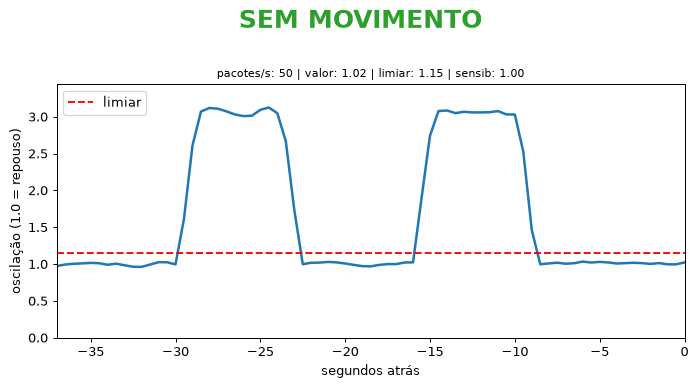


Resumo ao vivo: 75 leituras | em alerta 45.3% do tempo | 2 episodio(s) de alerta | pacotes invalidos: 0
Log salvo em demo_log\demo_log_2026-10-18_20-37-58.csv


In [26]:
%demo_ao_vivo --simular --calibracao 10 --duracao 48

Cada demonstração grava um log (`demo_log_<data>.csv`) com o valor medido, o limiar, os pacotes por segundo e o alerta de cada leitura. A célula abaixo desenha o log da última execução:

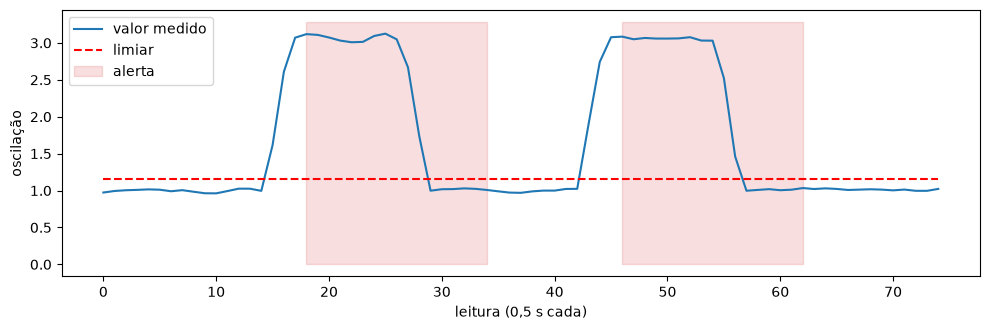

pacotes/s médio: 50 | leituras em alerta: 45.3%


In [27]:
log = pd.read_csv(demo_estado["log"])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(log.oscilacao.values, label="valor medido", color="#1f77b4")
ax.plot(log.limiar.values, "--", color="red", label="limiar")
ax.fill_between(range(len(log)), 0, log.oscilacao.max() * 1.05, where=log.alerta.values == 1,
                color="#d62728", alpha=0.15, label="alerta")
ax.set_xlabel("leitura (0,5 s cada)"); ax.set_ylabel("oscilação"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"pacotes/s médio: {log.pacotes_s.mean():.0f} | leituras em alerta: {log.alerta.mean():.1%}")

### 5.5 Ensaio com as suas gravações reais (replay)
Com `--replay` o programa **calibra com os primeiros 60 s de uma gravação de repouso** e depois reexibe outra gravação como se fosse ao vivo. Com `--velocidade 0` ele roda o mais rápido possível e imprime o resumo (use `--texto` para não gerar gráficos). Para um ensaio em tempo real, com o gráfico, use `--velocidade 1`.

Primeiro, **sem modelo** (limiar). O repouso é o vazio do dia 17; o resultado é o tempo em alerta de cada gravação:

In [28]:
%demo_ao_vivo --replay dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv --alvo dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv --velocidade 0 --texto

[replay] calibrando com dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv; reexibindo dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv
Calibrando por 60 s. Mantenha a area do link parada.
Calibrado: 50 pacotes/s | modo limiar=1.092

Resumo ao vivo: 3808 leituras | em alerta 4.4% do tempo | 7 episodio(s) de alerta | pacotes invalidos: 0
Log salvo em demo_log\demo_log_2026-10-18_20-38-47.csv


In [29]:
%demo_ao_vivo --replay dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv --alvo dados/andando/csi_andando_2026-10-16_18-12-39_ead31c83.csv --velocidade 0 --texto

[replay] calibrando com dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv; reexibindo dados/andando/csi_andando_2026-10-16_18-12-39_ead31c83.csv
Calibrando por 60 s. Mantenha a area do link parada.
Calibrado: 50 pacotes/s | modo limiar=1.092

Resumo ao vivo: 711 leituras | em alerta 90.7% do tempo | 10 episodio(s) de alerta | pacotes invalidos: 0
Log salvo em demo_log\demo_log_2026-10-18_20-38-56.csv


In [30]:
%demo_ao_vivo --replay dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv --alvo dados/sentado/csi_sentado_2026-10-16_15-04-10_5550a02f.csv --velocidade 0 --texto

[replay] calibrando com dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv; reexibindo dados/sentado/csi_sentado_2026-10-16_15-04-10_5550a02f.csv
Calibrando por 60 s. Mantenha a area do link parada.
Calibrado: 50 pacotes/s | modo limiar=1.092

Resumo ao vivo: 10233 leituras | em alerta 67.8% do tempo | 223 episodio(s) de alerta | pacotes invalidos: 0
Log salvo em demo_log\demo_log_2026-10-18_20-38-58.csv


> **Leitura:** o vazio da própria calibração fica com poucos alertas (falso alarme), a caminhada fica quase o tempo todo em alerta, e a sessão de 94 min (pessoa sentada, mexendo-se de vez em quando) fica em alerta na maior parte do tempo.

### 5.6 Árvore numa sessão que ela nunca viu
Para um teste honesto, treinamos a árvore **sem** a gravação de caminhada (`--excluir`) e reexibimos essa gravação com o modelo. `--sem-avaliacao` pula a validação, que já foi feita na seção 4.

In [31]:
%treinar_arvore --dados dados --excluir ead31c83 --sem-avaliacao --saida modelo_sem_andando.joblib

Lendo sessoes...
  (excluida por --excluir) csi_andando_2026-10-16_18-12-39_ead31c83.csv

classe    dia            min  pkt/s  sessao
andando   2026-10-15    16.8    1.1  -10-15_18-46-10_a8d0e595  <- DESCARTADA: taxa baixa (1.1 pacotes/s)
dormindo  2026-10-15     1.6    1.1  -10-15_23-43-03_2dd06e8c  <- DESCARTADA: taxa baixa (1.1 pacotes/s)
dormindo  2026-10-15     0.4   50.0  -10-15_23-45-09_af1239c2
sentado   2026-10-15    18.4    1.2  -10-15_19-52-56_7559963a  <- DESCARTADA: taxa baixa (1.2 pacotes/s)
sentado   2026-10-15    20.7    1.1  -10-15_21-48-51_7d8db410  <- DESCARTADA: taxa baixa (1.1 pacotes/s)
sentado   2026-10-15    16.9    1.0  -10-15_22-47-43_3220801e  <- DESCARTADA: taxa baixa (1.0 pacotes/s)
sentado   2026-10-15     0.4   50.2  -10-15_23-29-04_775cb428
sentado   2026-10-16     1.3   15.1  -10-16_10-08-46_1231fca5  <- DESCARTADA: taxa baixa (15.1 pacotes/s)
sentado   2026-10-16    10.8    7.6  -10-16_10-15-51_98eadacb  <- DESCARTADA: taxa baixa (7.6 pacotes/s)
sentad

In [32]:
%demo_ao_vivo --replay dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv --alvo dados/andando/csi_andando_2026-10-16_18-12-39_ead31c83.csv --modelo modelo_sem_andando.joblib --velocidade 0 --texto

[modelo] arvore carregada de modelos\modelo_sem_andando.joblib
[replay] calibrando com dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv; reexibindo dados/andando/csi_andando_2026-10-16_18-12-39_ead31c83.csv
Calibrando por 60 s. Mantenha a area do link parada.
Calibrado: 50 pacotes/s | modo ARVORE

Resumo ao vivo: 711 leituras | em alerta 98.9% do tempo | 1 episodio(s) de alerta | pacotes invalidos: 0
Log salvo em demo_log\demo_log_2026-10-18_20-39-19.csv


#### O que acontece se a calibração for de outro dia (uso errado)
Aqui a calibração usa o vazio do **dia 17** e a gravação reexibida é um vazio do **dia 16**, sem ninguém no quarto. Nada se moveu, mas a árvore acusa movimento boa parte do tempo, porque o "normal" aprendido era de outro dia:

In [33]:
%demo_ao_vivo --replay dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv --alvo dados/vazio/csi_vazio_2026-10-16_18-24-53_51bde2bf.csv --modelo modelo_sem_andando.joblib --velocidade 0 --texto

[modelo] arvore carregada de modelos\modelo_sem_andando.joblib
[replay] calibrando com dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv; reexibindo dados/vazio/csi_vazio_2026-10-16_18-24-53_51bde2bf.csv
Calibrando por 60 s. Mantenha a area do link parada.
Calibrado: 50 pacotes/s | modo ARVORE

Resumo ao vivo: 6257 leituras | em alerta 54.9% do tempo | 278 episodio(s) de alerta | pacotes invalidos: 0
Log salvo em demo_log\demo_log_2026-10-18_20-39-21.csv


> **Por isso a calibração tem que ser feita no local, minutos antes de usar** (e repetida se o ambiente mudar).

### 5.7 Ensaio em tempo real das gravações (plano B caso a captura ao vivo não funcione)
Reexibe as gravações reais em tempo real, com o gráfico. Serve para ensaiar a demonstração sem hardware ou como plano B (É uma gravação!). A caminhada dura 6 min; interrompa com ■ quando quiser.

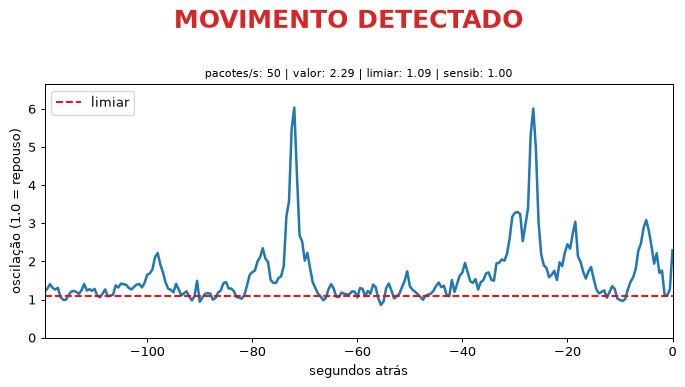


Resumo ao vivo: 711 leituras | em alerta 90.7% do tempo | 10 episodio(s) de alerta | pacotes invalidos: 0
Log salvo em demo_log\demo_log_2026-10-18_20-39-35.csv


In [34]:
%demo_ao_vivo --replay dados/vazio/csi_vazio_2026-10-17_16-33-53_8edca7e4.csv --alvo dados/andando/csi_andando_2026-10-16_18-12-39_ead31c83.csv --velocidade 1

> **Google Colab:** a seção 5.8 (e o `--serial`/`--ip` da demo) **não funciona no Colab**, porque o Colab roda num servidor na nuvem e não enxerga a porta USB do seu ESP32 nem a sua rede local. No Colab use o treino (seção 4), o ensaio simulado (5.4) e o replay das gravações (5.5 a 5.7). A demo ao vivo com o ESP32 precisa rodar no computador onde ele está ligado. O Colab apaga `modelos/`, `demo_log/` e `.cache_csi/` ao encerrar a sessão: baixe o `.joblib` que quiser guardar.

### 5.8 Execução real, com o ESP32
Antes de rodar:

- o ESP32 está ligado na USB e conectado ao WiFi; **o IP dele aparece quando ele liga**;
- o PC e o ESP32 estão na **mesma rede**;
- o **Serial Monitor do PlatformIO está fechado** (a porta só abre em um programa por vez).

Depois do comando, a área entre o ESP32 e o roteador deve ficar **parada** durante a calibração. O gráfico mostra `pacotes/s`; o ideal é perto de 50. Se aparecer **TAXA BAIXA**, a captura está perdendo dados.

Primeiro com o **limiar** (não precisa de modelo treinado):

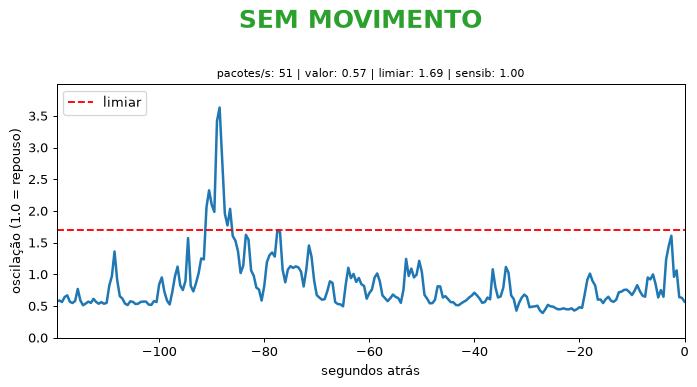

In [ ]:
%demo_ao_vivo --ip 192.168.1.165 --serial COM13 --calibracao 60

Depois com a **árvore** (precisa do `modelo_arvore.joblib` gerado na seção 4):

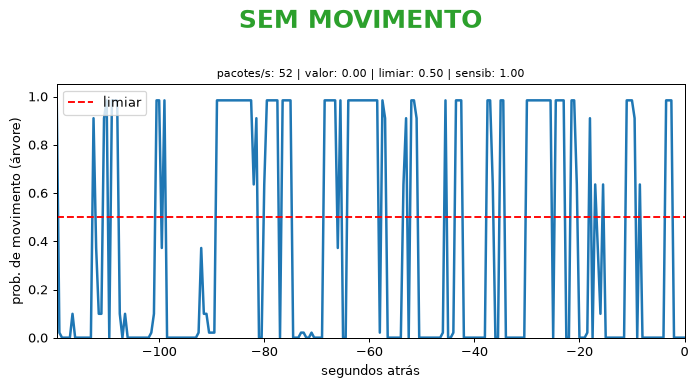


Resumo ao vivo: 299 leituras | em alerta 50.5% do tempo | 11 episodio(s) de alerta | pacotes invalidos: 1747
Log salvo em demo_log\demo_log_2026-10-18_19-02-15.csv


In [ ]:
%demo_ao_vivo --ip 192.168.1.165 --serial COM13 --calibracao 30 --modelo modelo_arvore.joblib

> Se o modo árvore der falso alarme com tudo parado, rode sem `--modelo`, ou aumente o limiar da árvore (diminua `--sensib`, por exemplo `--sensib 0.8`). Para recalibrar, basta executar a célula de novo.

## 6. Limitações e conclusões
- O sinal de WiFi **tem informação de movimento**: nas gravações reais, a caminhada e a pessoa sentada que se mexe ficam bem acima do repouso do dia, e uma árvore rasa as separa do vazio.
- A árvore final é praticamente **um corte em `osc_p90`**. É um resultado honesto: com poucas sessões, o sinal tem uma dimensão útil.
- A validação mais exigente (sessão inteira de fora) mostrou o ponto fraco: o **vazio de outro dia pode gerar falso alarme** (seção 4.6) quando o treino não tem um vazio daquele dia. A solução é gravar **mais sessões de vazio, a ~50 pacotes/s, em mais dias**.
- **Calibrar com o repouso de outro dia não funciona** (seção 5.6): o "normal" muda de um dia para o outro. Calibre sempre no local, antes de usar.
- **Pessoa sentada e quieta é pouco detectável**: o CSI de amplitude reage a mudanças, e quem está parado quase não muda o canal. A demonstração detecta **movimento**, não presença.
- Medidas que identificam a sessão (como o formato médio do espectro) dão resultados falsos de 100% e foram deixadas de fora (seção 4.7). Valide sempre com um **vazio de outro dia** como controle negativo.
- As sessões de taxa baixa (~1 pacote/s) foram descartadas; mantenha **50 pacotes/s** em todas as gravações novas.

**Próximos passos:** gravar mais sessões alternando vazio e pessoa em vários dias, retreinar com `%treinar_arvore` e conferir o controle negativo antes de confiar no modelo.